# MCF10A differential phase and absorption imaging


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `mcf10a_dpc_phase_absorption` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：intensities (1, 4, 512, 512) uint16：Original measured detector ADU, axes batch, illumination(top,bottom,left,right),row,column。恢复目标：光学phase rad及有符号absorption ln|T|。

获取模型：weak-object phase与absorption经两个WOTF卷积叠加成normalized intensity。实际恢复算法：solvers.reconstruct/normal_matrix/invert：Fourier域2x2 Tikhonov逆；tv_solve另作比较。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:15为原始标准方法结果，无独立生物phase真值。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：mcf10a_dpc_phase_absorption.ipynb单元0：5. Results；mcf10a_dpc_phase_absorption.ipynb单元3有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元1, 3（从0计数）。代码单元4个，带execution_count的4个，保存PNG输出5幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：参考只做数值比较；现有图展示fresh Tikhonov/TV，没有直接绘制original phase/absorption目标图。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


Four real asymmetric-illumination exposures of MCF10A cells encode two spatial optical unknowns. The central512×512native detector region was fixed before the oracle run; its83.2µmfield retains all four measured illumination conditions. This active notebook computes the published weak-object Tikhonov inverse and the original upstream notebook third-order-TV comparison.

## 2. Data

| Key | Shape | Dtype | Description |
|---|---|---|---|
| intensities | (1, 4, 512, 512) | uint16 | Original measured detector ADU, axes batch, illumination(top,bottom,left,right),row,column |

The fixed central512×512native detector region retains all four illumination exposures and has83.2µmfield width. No image resizing or precision conversion has been applied.

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Wavelength | 0.514 | µm | Green illumination central wavelength |
| Objective numerical aperture | 0.4 | dimensionless | Circularobjective pupil |
| Illumination numerical aperture | 0.4 | dimensionless | Half-circular brightfield source |
| Inner illumination numerical aperture | 0.0 | dimensionless | No source annular hole |
| Magnification | 40.0 | dimensionless | 20× objective plus2× front-port magnification |
| Camera pixel pitch | 6.5 | µm | Original detector pitch |
| Object pixel pitch | 0.1625 | µm | Native camera/magnification ratio |
| Source rotations | 0,180,90,270 | degree | Source patterns in top,bottom,left,right order under declared FFT coordinates |
| LED spacing | 4 | mm | Original array spacing |
| Array to specimen distance | 69.5 | mm | Original illumination geometry |
| Native full acquisition | 2160 rows ×2560 columns | pixel | Bound region chosen before inversion |
| Bound native ROI | rows824:1336,columns1024:1536 | zero-based half-open pixel | Fixed central region, no reconstruction-dependent selection |
| Bound field width | 83.2 | µm | 512 native pixels per axis |
| Spatial boundary | periodic discrete weak-object operator | dimensionless | No implicit padding, crop or alignment during evaluation |
| Detector precision | unsigned 16-bit | ADU | Preserved observations |
| Noise variance | not calibrated | unavailable | No independently measured noise variance provided |

## 3. Physics

### Phase-delay convention verified independently
The original numerical output phi is retained as phase delay, with physical complex transmission T=exp(u−i phi). Its optical complex argument under the alternative exp(u+i theta) convention is theta=−phi. An independent incoherent sum of pupil-filtered plane waves validates this sign explicitly. Original outputs and frozen fixtures remain unchanged; neither reference fitting nor tolerance adjustment is used to reconcile the conventions.

For four illumination states $j$, normalized intensity contrasts satisfy

$$
d_j=h_{u,j}*u+h_{\phi,j}*\phi+\eta_j.
$$

$u=\log$ amplitude transmission is dimensionless and signed; $\phi$ is phase delay in radians. In this convention the physical complex transmission is $T=\exp(u-\mathrm i\phi)$. Transfer kernels $h$ follow independently specified source/pupil geometry, and $\eta$ includes model mismatch. Periodic convolution and the weak-object approximation limit interpretation; no refractive-index or thickness map is directly identified.

## 4. Method

### Acquisition, mathematics and interpretation
The normalized intensities obey d_j=h_u,j*u+h_phi,j*phi, where j indexes illumination, u=ln(amplitude transmission) is the signed dimensionless absorption potential, phi is optical phase inrad, and the two convolution kernels are determined by the independent illumination/pupil geometry. The first-order weak-object approximation omits higher-order scattering. The4asymmetric source patterns resolve the directional phase-frequency gaps of individual exposures.

At each Fourier frequency, assemble the2×2normal matrix from both transfer columns, add the fixed quadratic penalties0.1and0.005to its diagonal, and solve its determinant formula explicitly. The phase piston is unobservable and fixed by the inverse zero-frequency convention.

For the scientifically relevant upstream TV comparison, the local implementation actively runs the original10ADMMupdates with third-order periodic finite differences, joint isotropic shrinkage, tau=1andrho=1. It is a genuine computed comparison, not an archived reconstruction substituted for a fresh result. The five figure groups preserve the supplied notebook raw-image/source-pattern/transfer-function/Tikhonov/TV comparisons, and add measured iteration, residual, sensitivity and profile evidence.

At each Fourier frequency collect transfer columns in $H$ and data in $d$. The two-field Tikhonov inverse evaluates

$$
\widehat v=[H^*H+\operatorname{diag}(0.1,0.005)]^{-1}H^*d,\quad v=(u,\phi)^T,
$$

by the explicit two-by-two determinant formula, using the stored transfer-column order. Phase piston is set by the zero-frequency convention. The separate ten-update third-order-TV ADMM comparison uses periodic differences and joint isotropic shrinkage; it remains distinct from the selected quadratic inverse.

## 5. Results

The acquisition, source/transfer panels, Tikhonov/TV comparison and sensitivity figures are generated from active local calls. The frozen scalar ledger at the end documents a separately identified cleaned run; it is not the source of plotted reconstructions.


In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import run_experiments,make_figures
data=load_data(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as f: upstream={k:f[k].copy() for k in f.files}
start=time.perf_counter()
experiments=run_experiments(data,upstream)
print(json.dumps({'fresh_runtime_s':time.perf_counter()-start,**experiments['metrics']},indent=2))

{
  "fresh_runtime_s": 3.885821899999428,
  "reconstruction_upstream_relative_l2": 0.0,
  "absorption_upstream_relative_l2": 0.0,
  "tikhonov_observation_residual": 0.4790021710858714
}


In [2]:
with np.load(root/'notebooks/reference_outputs/upstream_tv.npz',allow_pickle=False) as f:
    upstream_tv={k:f[k].copy() for k in f.files}
from src.visualization import error
print({k+'_TV_vs_original':error(experiments['tv'][k],upstream_tv[k]) for k in upstream_tv})

{'reconstruction_TV_vs_original': 0.0, 'absorption_TV_vs_original': 0.0}


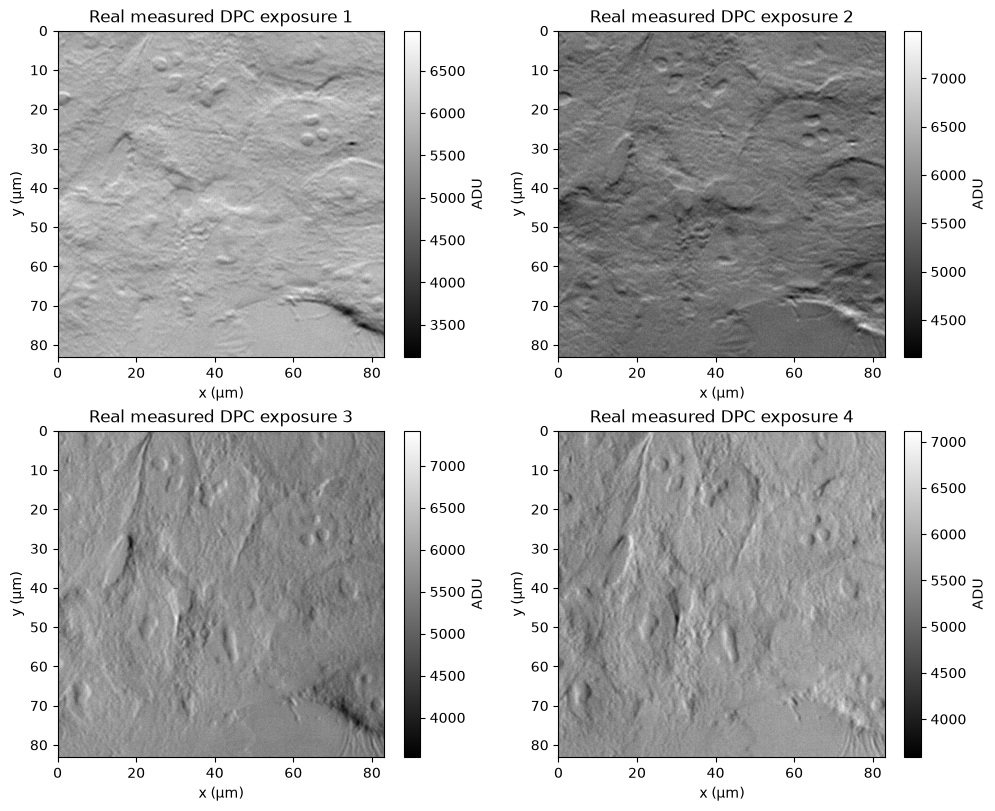

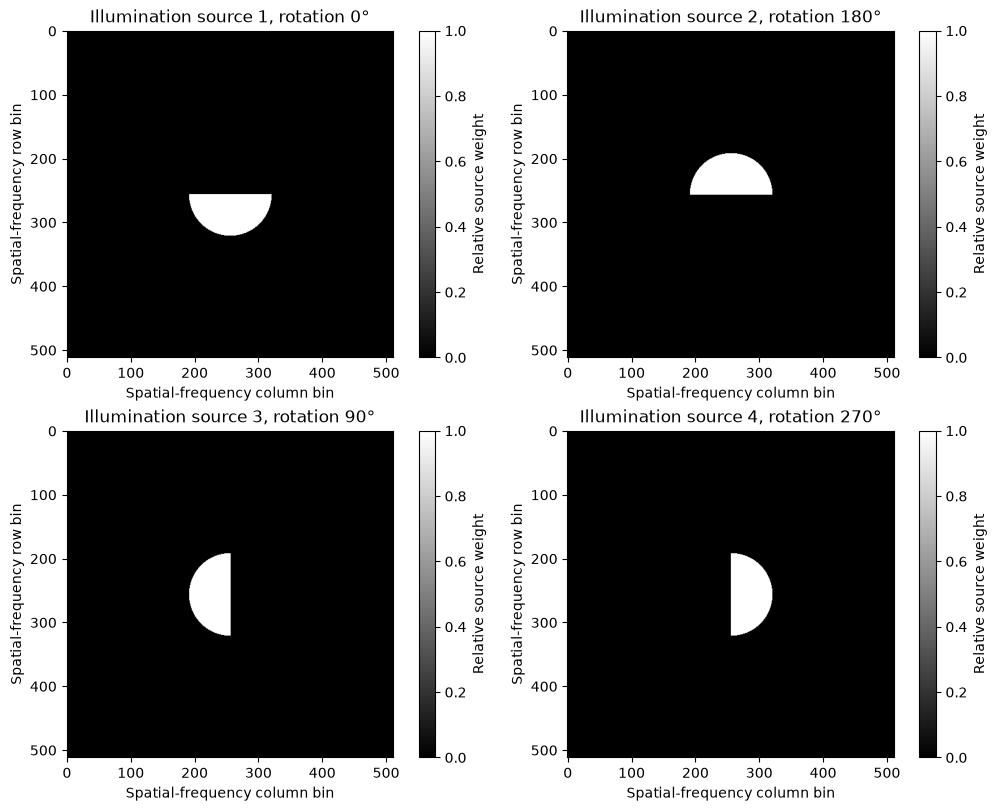

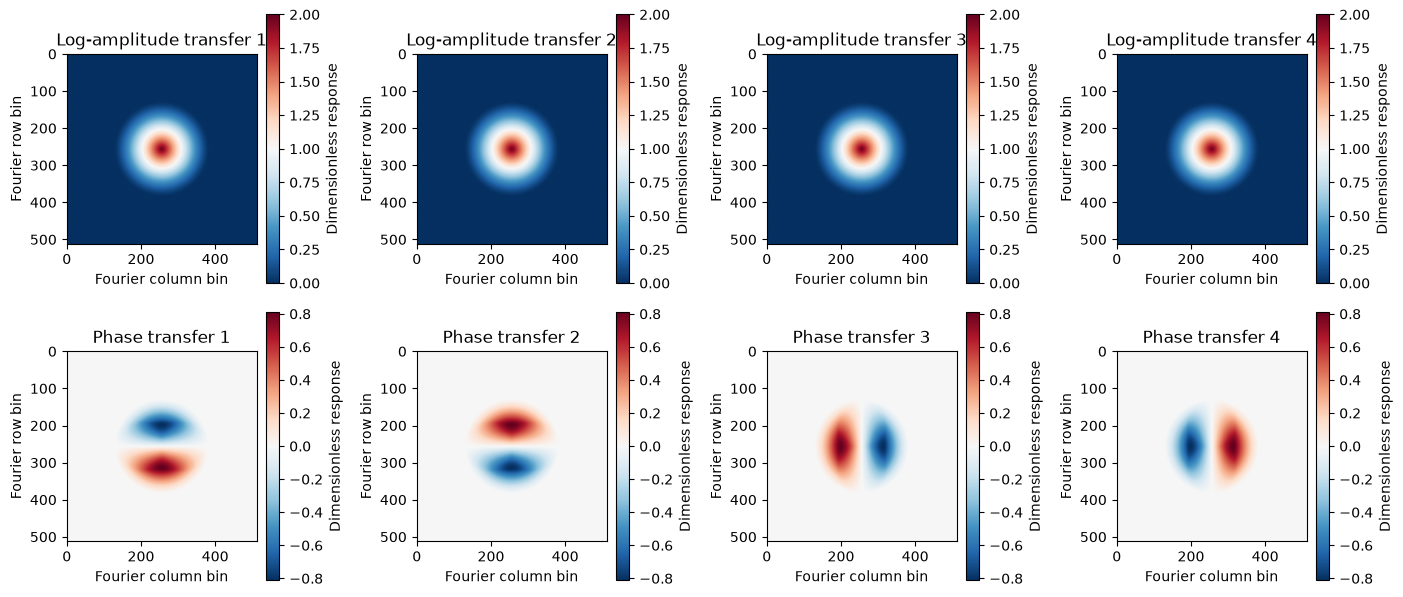

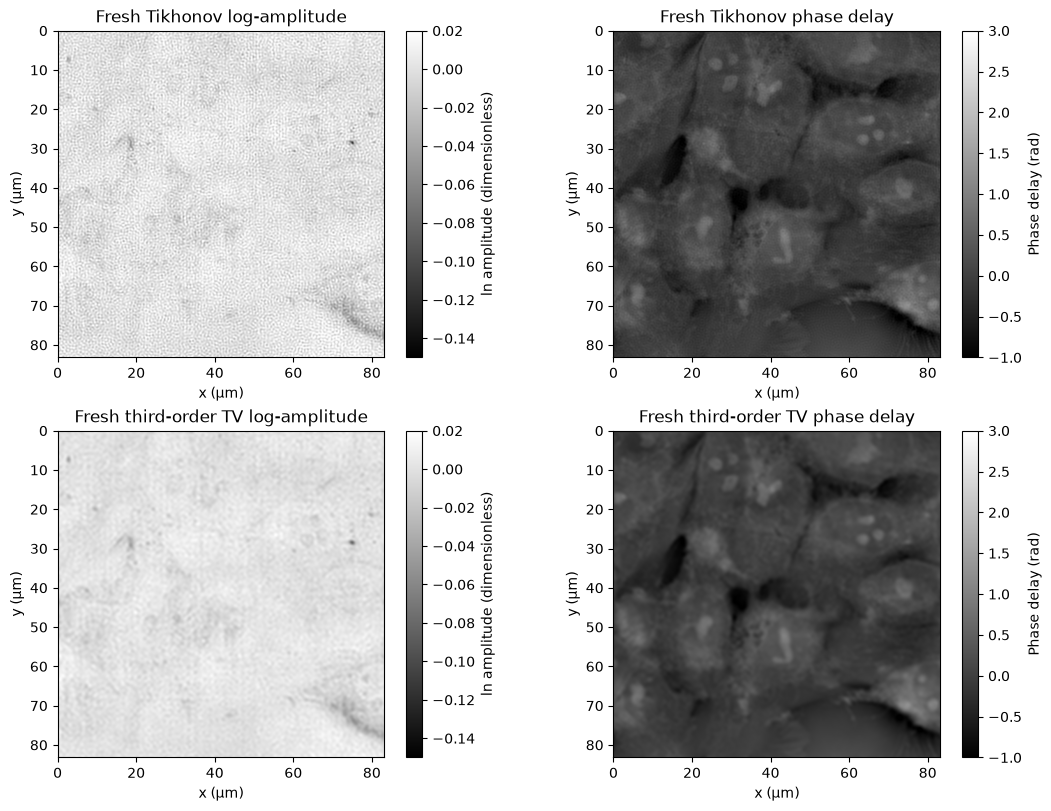

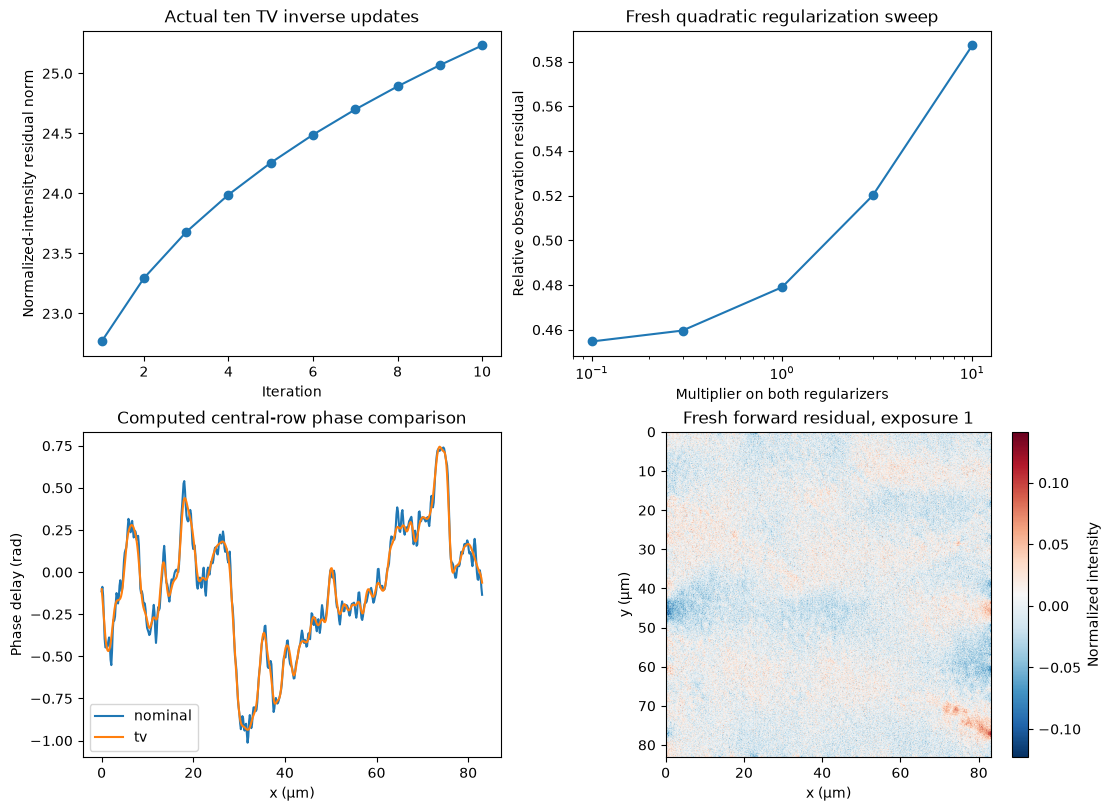

In [3]:
figures=make_figures(data,experiments)
for fig in figures:
    display(fig)
    plt.close(fig)

The following separately identified cleaned-run measurements are frozen scalar results from this task’s fresh local experiment run. The active reconstruction above remains the source of every plotted result; this archive records numeric provenance rather than supplying a reconstruction.


In [4]:
with np.load(root / 'notebooks/reference_outputs/cleaned_metrics.npz', allow_pickle=False) as recorded:
    print('Separately archived fresh cleaned-run measurements:', {k: recorded[k].tolist() for k in recorded.files})


Separately archived fresh cleaned-run measurements: {'reconstruction_upstream_relative_l2': 0.0, 'absorption_upstream_relative_l2': 0.0, 'tikhonov_observation_residual': 0.4790021710858714}


## 6. Conclusion

### Interpretation

Independent original-stage fixtures validate normalization, source patterns, both weak-object transfer functions, and both complete reconstruction methods. The signed absorption potential is log transmission, not a positive linear attenuation coefficient. Neither optical phase nor its standard-method reference is relabeled as refractive index, thickness or biological ground truth. Periodic inversion boundaries and observed-image shading normalization can generate boundary/low-frequency artifacts; all results retain the prescribed region and scale without fitted registration.
